**Práctica 1**

Notebook avanzado orientado a realizar comparaciones detalladas entre heurísticas. 

Incluye visualización gráfica y análisis cuantitativo para apoyar la justificación de resultados.


# Análisis de Algoritmos de Búsqueda
Comparación estadística entre A* MD + LC y Voraz Manhattan sobre n puzzles aleatorios.

Métricas a comparar:
- Coste de la solución (número de movimientos)
- Nodos expandidos
- Tiempo de ejecución
- Diferencia entre soluciones

En principio si usas Polilabs no necesitas instalar nada, si lo usas en otro ordenador es posible que tengas que instalar alguno de estos paquetes:

**pip install matplotlib tabulate numpy**

In [1]:
# Importar librerías necesarias
import search
from search import *
import time
import statistics
import matplotlib.pyplot as plt

## Configuración y Ejecución del Experimento

In [2]:
# Configuración
size = 3  # Tamaño del puzzle
num_iterations = 1000  # Número de puzzles aleatorios
end_state = generate_spiral_state(size)

# Estructuras para almacenar resultados
astar_costs = []
astar_expanded = []
astar_times = []
greedy_costs = []
greedy_expanded = []
greedy_times = []
cost_differences = [] 
time_differences = [] 

print(f"Iniciando experimento con {num_iterations} puzzles {size}x{size}")
print("Estado objetivo:")
visualize_state(end_state)

# Bucle principal del experimento
for i in range(num_iterations):
    # Generar estado inicial aleatorio
    initial_state = generate_random_state(size, end_state)
    
    if not isSolvable(initial_state, end_state):
        print(f"\nPuzzle {i+1}: No tiene solución, generando otro...")
        continue
        
    print(f"\rProcesando puzzle {i+1}/{num_iterations}", end='', flush=True)
    
    # A* MD + LC

    result = run_algorithm('A (MD + LC)', initial_state, end_state, size)

    astar_result = result['A (MD + LC)']
    
    # Voraz Manhattan

    result = run_algorithm('Voraz (Manhattan)', initial_state, end_state, size)

    greedy_result = result['Voraz (Manhattan)']
    
    # Guardar resultados

    astar_costs.append(astar_result['cost'])
    astar_expanded.append(astar_result['nodes_expanded'])
    astar_times.append(astar_result['time'])
    
    greedy_costs.append(greedy_result['cost'])
    greedy_expanded.append(greedy_result['nodes_expanded'])
    greedy_times.append(greedy_result['time'])
    
    cost_diff = greedy_result['cost'] - astar_result['cost']
    cost_differences.append(cost_diff)
        
    time_diff = astar_result['time'] - greedy_result['time']
    time_differences.append(time_diff)
        


print("\nExperimento completado!")

Iniciando experimento con 1000 puzzles 3x3
Estado objetivo:
 1  2  3
 8     4
 7  6  5
Procesando puzzle 1/1000A (MD + LC) executed
Voraz (Manhattan) executed
Procesando puzzle 2/1000A (MD + LC) executed
Voraz (Manhattan) executed
Procesando puzzle 3/1000A (MD + LC) executed
Voraz (Manhattan) executed
Procesando puzzle 4/1000A (MD + LC) executed
Voraz (Manhattan) executed
Procesando puzzle 5/1000A (MD + LC) executed
Voraz (Manhattan) executed
Procesando puzzle 6/1000A (MD + LC) executed
Voraz (Manhattan) executed
Procesando puzzle 7/1000A (MD + LC) executed
Voraz (Manhattan) executed
Procesando puzzle 8/1000A (MD + LC) executed
Voraz (Manhattan) executed
Procesando puzzle 9/1000A (MD + LC) executed
Voraz (Manhattan) executed
Procesando puzzle 10/1000A (MD + LC) executed
Voraz (Manhattan) executed
Procesando puzzle 11/1000A (MD + LC) executed
Voraz (Manhattan) executed
Procesando puzzle 12/1000A (MD + LC) executed
Voraz (Manhattan) executed
Procesando puzzle 13/1000A (MD + LC) executed


## Análisis de Resultados

In [3]:
# Calcular estadísticas
stats = {
    'A*': {
        'coste_min': min(astar_costs),
        'coste_max': max(astar_costs),
        'coste_medio': statistics.mean(astar_costs),
        'expandidos_medio': statistics.mean(astar_expanded),
        'tiempo_medio': statistics.mean(astar_times)
    },
    'Voraz': {
        'coste_min': min(greedy_costs),
        'coste_max': max(greedy_costs),
        'coste_medio': statistics.mean(greedy_costs),
        'expandidos_medio': statistics.mean(greedy_expanded),
        'tiempo_medio': statistics.mean(greedy_times)
    }
}

print("Estadísticas de A* MD LC:")
print(f"Coste - Min: {stats['A*']['coste_min']}, Max: {stats['A*']['coste_max']}, Media: {stats['A*']['coste_medio']:.2f}")
print(f"Nodos expandidos (media): {stats['A*']['expandidos_medio']:.2f}")
print(f"Tiempo medio: {stats['A*']['tiempo_medio']:.3f}s\n")

print("Estadísticas de Voraz Manhattan:")
print(f"Coste - Min: {stats['Voraz']['coste_min']}, Max: {stats['Voraz']['coste_max']}, Media: {stats['Voraz']['coste_medio']:.2f}")
print(f"Nodos expandidos (media): {stats['Voraz']['expandidos_medio']:.2f}")
print(f"Tiempo medio: {stats['Voraz']['tiempo_medio']:.3f}s\n")

print("Diferencias de coste (Voraz - A*):")
print(f"Mínima: {min(cost_differences)}")
print(f"Máxima: {max(cost_differences)}")
print(f"Media: {statistics.mean(cost_differences):.2f}")

Estadísticas de A* MD LC:
Coste - Min: 7, Max: 29, Media: 21.50
Nodos expandidos (media): 308.52
Tiempo medio: 0.021s

Estadísticas de Voraz Manhattan:
Coste - Min: 7, Max: 93, Media: 51.31
Nodos expandidos (media): 273.52
Tiempo medio: 0.004s

Diferencias de coste (Voraz - A*):
Mínima: 0
Máxima: 72
Media: 29.81


## Visualización de Resultados

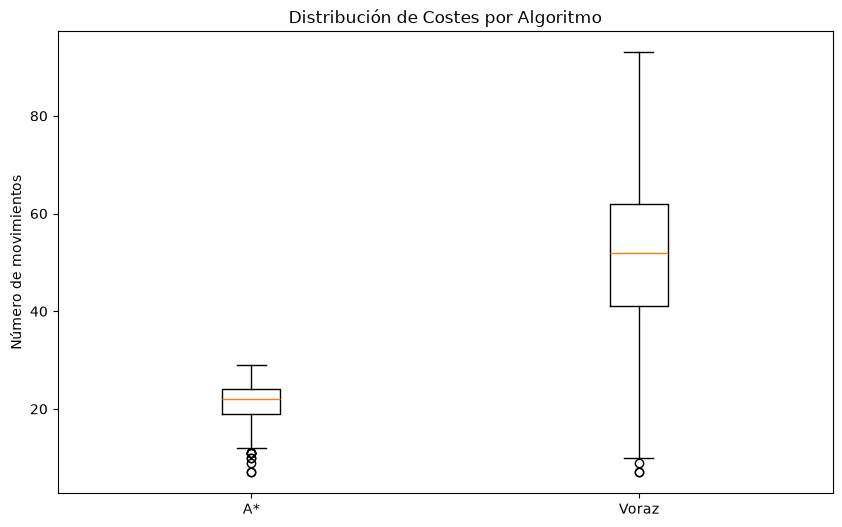

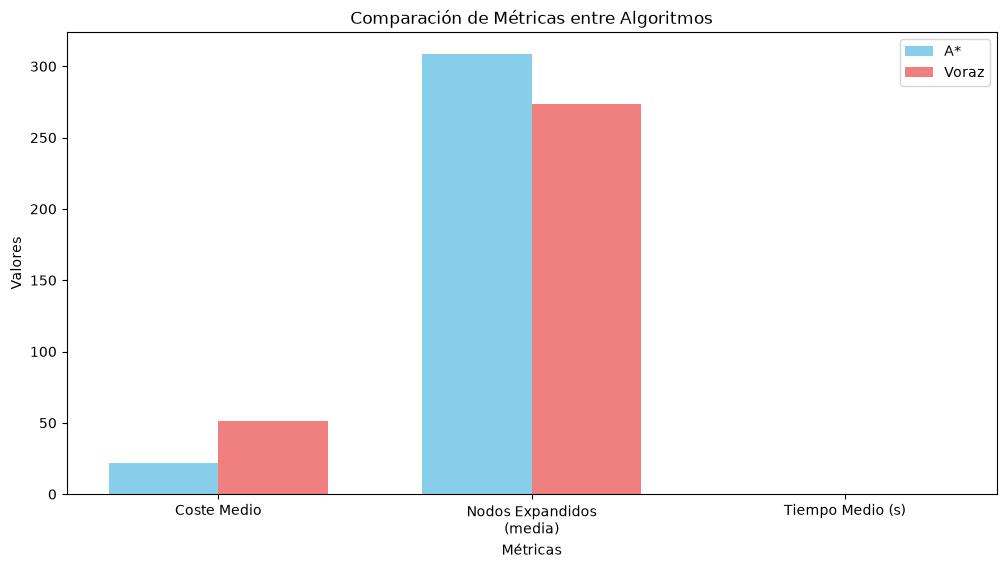

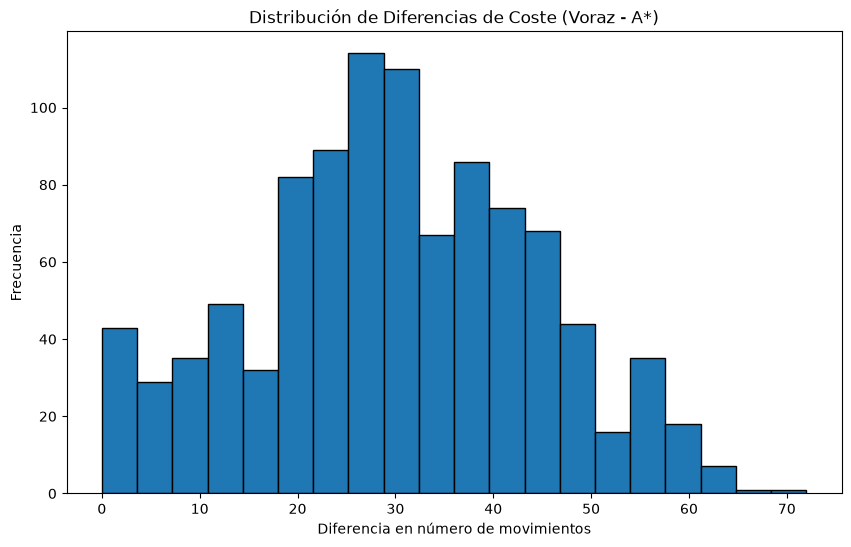

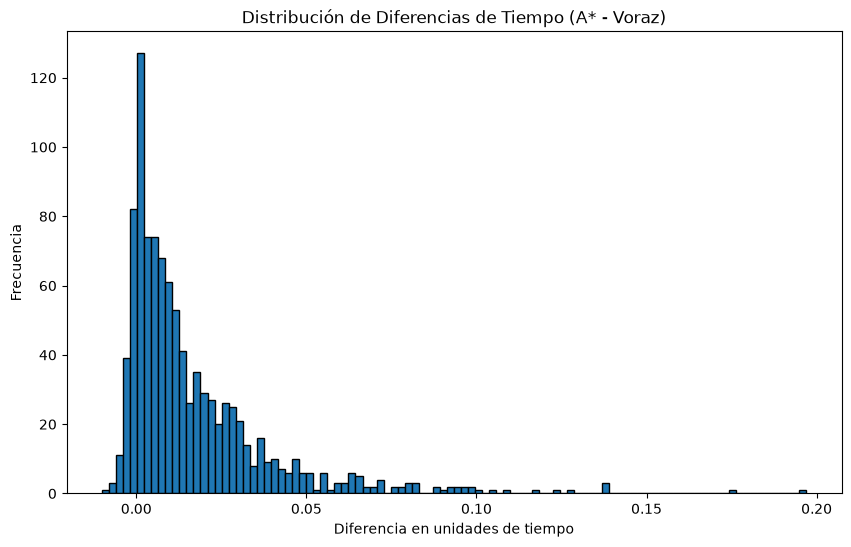

In [4]:
# Gráfico de cajas para costes
plt.figure(figsize=(10, 6))
plt.boxplot([astar_costs, greedy_costs])
plt.title('Distribución de Costes por Algoritmo')
plt.ylabel('Número de movimientos')
plt.xticks([1, 2], ['A*', 'Voraz'])  # ← Aquí estableces las etiquetas
plt.show()


# Gráfico de barras para promedios
metrics = ['Coste Medio', 'Nodos Expandidos\n(media)', 'Tiempo Medio (s)']
astar_values = [stats['A*']['coste_medio'], stats['A*']['expandidos_medio'], stats['A*']['tiempo_medio']]
greedy_values = [stats['Voraz']['coste_medio'], stats['Voraz']['expandidos_medio'], stats['Voraz']['tiempo_medio']]

plt.figure(figsize=(12, 6))
x = range(len(metrics))
width = 0.35

plt.bar([i - width/2 for i in x], astar_values, width, label='A*', color='skyblue')
plt.bar([i + width/2 for i in x], greedy_values, width, label='Voraz', color='lightcoral')

plt.xlabel('Métricas')
plt.ylabel('Valores')
plt.title('Comparación de Métricas entre Algoritmos')
plt.xticks(x, metrics)
plt.legend()
plt.show()

# Histograma de diferencias de coste
plt.figure(figsize=(10, 6))
plt.hist(cost_differences, bins=20, edgecolor='black')
plt.title('Distribución de Diferencias de Coste (Voraz - A*)')
plt.xlabel('Diferencia en número de movimientos')
plt.ylabel('Frecuencia')
plt.show()

# Histograma de diferencias de tiempo
plt.figure(figsize=(10, 6))
plt.hist(time_differences, bins=100, edgecolor='black')
plt.title('Distribución de Diferencias de Tiempo (A* - Voraz)')
plt.xlabel('Diferencia en unidades de tiempo')
plt.ylabel('Frecuencia')
plt.show()